# BS49903 · DS/AI for Biology
## Week 7 Practice Notebook — Image Processing

Covers Week 7 (images as arrays, histograms, brightness and contrast, normalization,
histogram equalization).

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, io, exposure

def show(img, title="", ax=None):
    ax = ax or plt.gca()
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title); ax.axis("off")

def hist(img, title="", ax=None, bins=256):
    ax = ax or plt.gca()
    ax.hist(img.ravel(), bins=bins, range=(0, 256))
    ax.set_title(title); ax.set_xlabel("intensity"); ax.set_yticks([])

---
# Part 1 · An image is a 2D array

### 1.1 Shape and indexing: `img[i, j]`, row first

In [37]:
img = data.cell()                 # quantitative phase image of a cell

print(img.shape)                  # (h, w) = (rows, columns)
print(img.dtype)                  # uint8
print(img[0, 0])                  # top-left pixel

(660, 550)
uint8
71


In [38]:
patch = img[396:404, 365:373]     # the 8 x 8 patch from the lecture
print(patch)
print(patch.shape)
print(patch[3, 5])                # 93
print(patch[1:5, 2:4].shape)      # (4, 2): rows 1-4, columns 2-3

[[ 50  58  69  82  98 113 126 135]
 [ 47  55  64  77  91 106 119 130]
 [ 45  52  61  72  85  99 113 124]
 [ 44  50  58  68  80  93 107 119]
 [ 42  48  55  64  75  87 101 113]
 [ 41  46  52  60  70  82  95 107]
 [ 39  44  49  56  65  76  88 101]
 [ 37  41  47  53  61  70  82  95]]
(8, 8)
93
(4, 2)


Slices are `start:stop` with `stop` excluded, on both axes. `patch[1:5, 2:4]` is 4 rows × 2 columns.

### 1.2 Resolution sets the size of the array

Keeping every 4th pixel imitates imaging the same area at 4× lower resolution.

(660, 550) -> (165, 138)


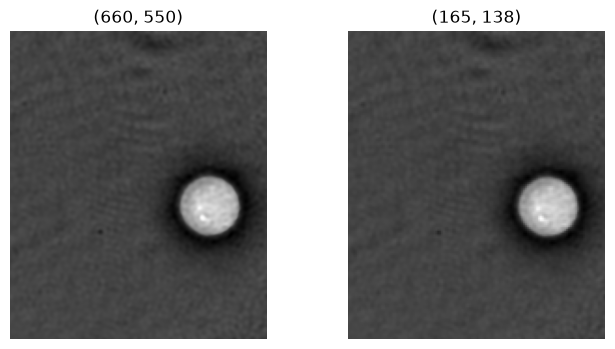

In [39]:
low = img[::4, ::4]
print(img.shape, "->", low.shape)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
show(img, f"{img.shape}", ax[0]); show(low, f"{low.shape}", ax[1])
plt.show()

---
# Part 2 · Data type and color

### 2.1 dtype decides the range, and arithmetic can overflow

In [40]:
for dt in [np.uint8, np.uint16]:
    print(dt.__name__, np.iinfo(dt).min, "-", np.iinfo(dt).max)

a = np.array([250], dtype=np.uint8)
print(a + 10)                     # [4]  wraps around, no error!
print(a.astype(int) + 10)         # [260]  cast first, then clip if needed

uint8 0 - 255
uint16 0 - 65535
[4]
[260]


Always cast to `int` or `float` before adding or multiplying a uint8 image.

### 2.2 Color images are multi-channel grayscale images

(512, 512, 3) uint8


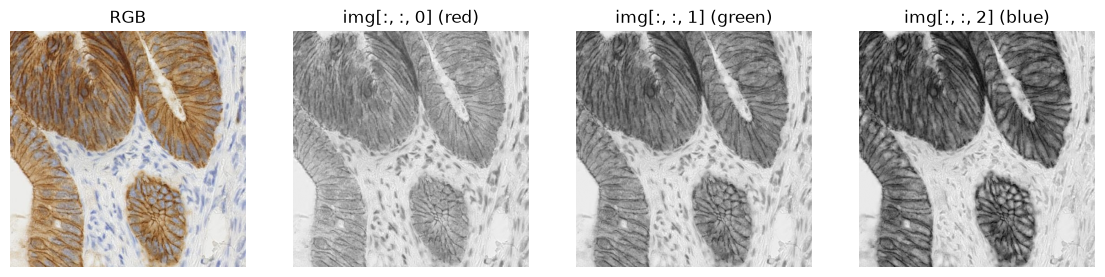

In [41]:
rgb = data.immunohistochemistry()
print(rgb.shape, rgb.dtype)       # (h, w, 3)

fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
ax[0].imshow(rgb); ax[0].set_title("RGB"); ax[0].axis("off")
for c, name in enumerate(["red", "green", "blue"]):
    show(rgb[:, :, c], f"img[:, :, {c}] ({name})", ax[c + 1])
plt.show()

---
# Part 3 · Inspect, then histogram

### 3.1 Five numbers before you compute

In [42]:
print("shape:", img.shape, " dtype:", img.dtype)
print("min / max:", img.min(), img.max())
print("mean / std:", round(img.mean(), 1), round(img.std(), 1))

shape: (660, 550)  dtype: uint8
min / max: 0 255
mean / std: 68.0 23.9


### 3.2 The histogram: how many pixels have each value k

(256,) True


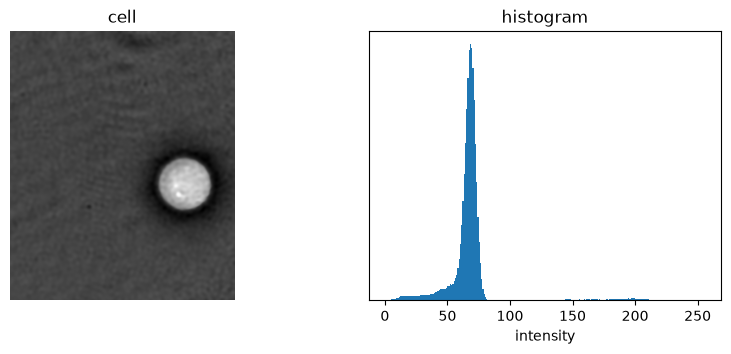

In [43]:
h = np.bincount(img.ravel(), minlength=256)    # h[k] = number of pixels with value k
print(h.shape, h.sum() == img.size)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
show(img, "cell", ax[0]); hist(img, "histogram", ax[1]); plt.show()

---
# Part 4 · Point operations: s = T(r)

Every pixel goes through the same function T, independently of its neighbors.

### 4.1 Brightness: s = clip(r + β, 0, L − 1)

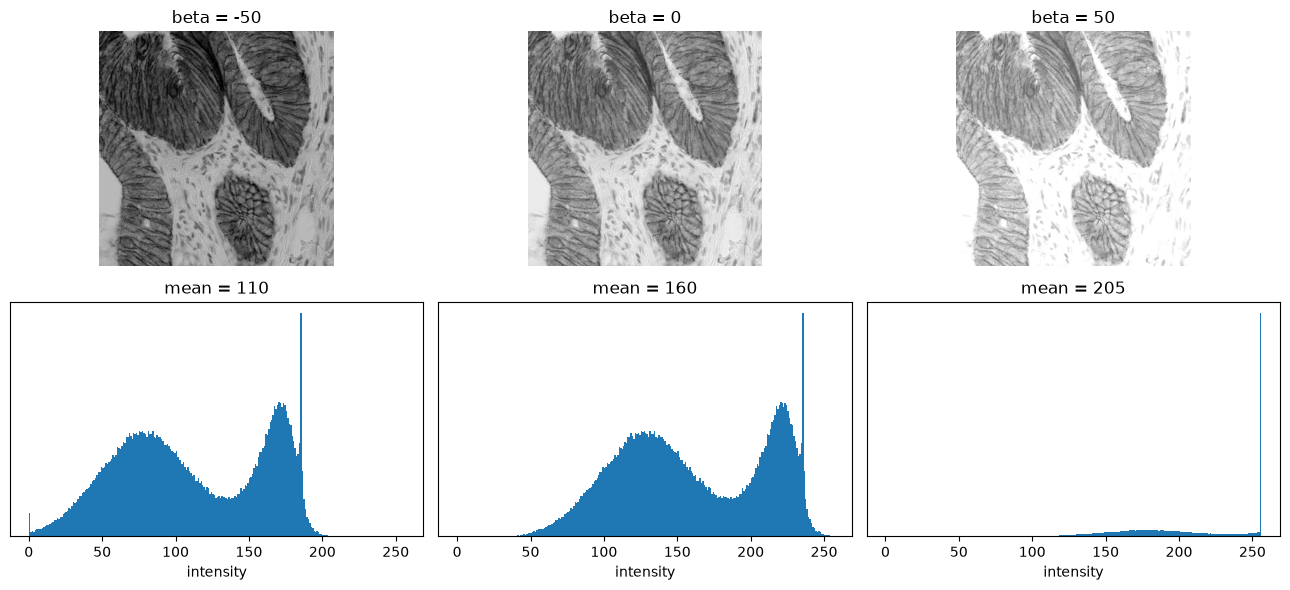

In [44]:
gray = (data.immunohistochemistry().mean(axis=2)).astype(np.uint8)   # simple grayscale

def brightness(r, beta):
    return np.clip(r.astype(int) + beta, 0, 255).astype(np.uint8)

fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for k, beta in enumerate([-50, 0, 50]):
    out = brightness(gray, beta)
    show(out, f"beta = {beta}", ax[0, k])
    hist(out, f"mean = {out.mean():.0f}", ax[1, k])
plt.tight_layout(); plt.show()

The histogram shifts by β and the mean follows it, until pixels pile up at 0 or 255.
How many pixels are lost to clipping with β = +50?

### 4.2 Contrast: s = clip(α(r − μ) + μ, 0, L − 1)

alpha = 0.5:  mean =  159.7   std =  24.8
alpha = 1.0:  mean =  160.0   std =  49.5
alpha = 1.8:  mean =  154.7   std =  81.7


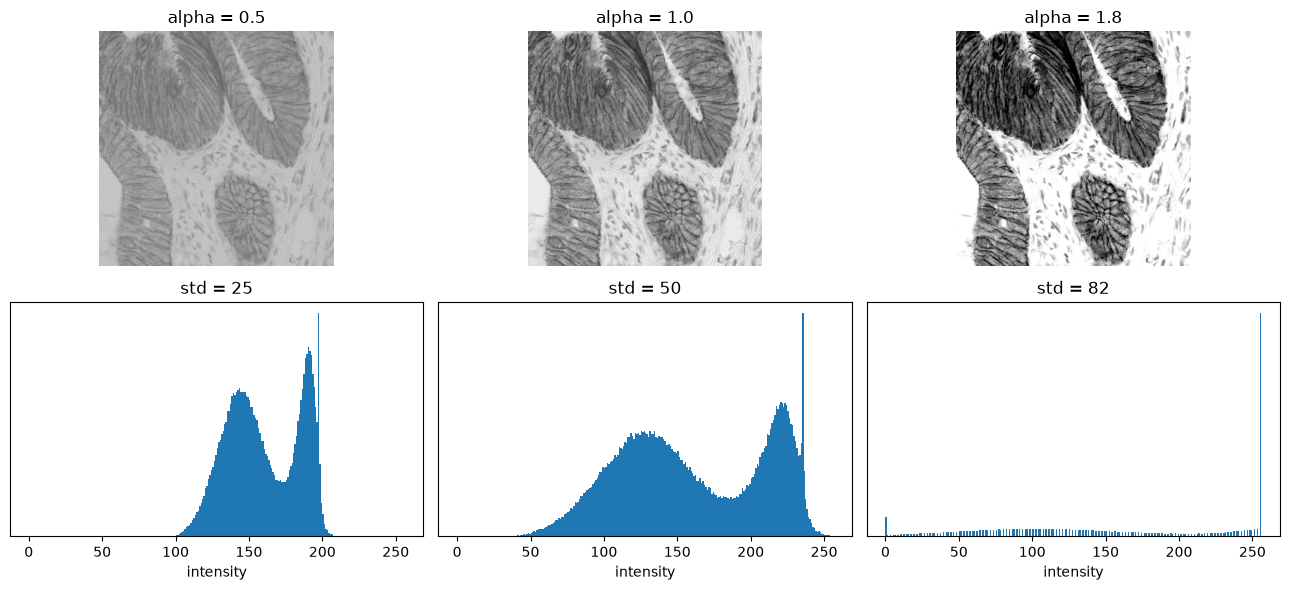

In [47]:
def contrast(r, alpha):
    mu = r.mean()
    return np.clip(alpha * (r.astype(float) - mu) + mu, 0, 255).astype(np.uint8)

for alpha in [0.5, 1.0, 1.8]:
    out = contrast(gray, alpha)
    print(f"alpha = {alpha}:  mean = {out.mean():6.1f}   std = {out.std():5.1f}")

fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for k, alpha in enumerate([0.5, 1.0, 1.8]):
    out = contrast(gray, alpha)
    show(out, f"alpha = {alpha}", ax[0, k])
    hist(out, f"std = {out.std():.0f}", ax[1, k])
plt.tight_layout(); plt.show()

α scales the standard deviation (until clipping kicks in), and μ keeps the mean roughly fixed.

---
# Part 5 · Normalization is linear

In [48]:
em = io.imread("em.tif").astype(np.uint8)
print(em.shape, em.min(), em.max(), round(em.mean(), 1), round(em.std(), 1))

(576, 576) 33 255 128.0 40.0


### 5.1 Min–max normalization: s = (L − 1)(r − r_min)/(r_max − r_min)

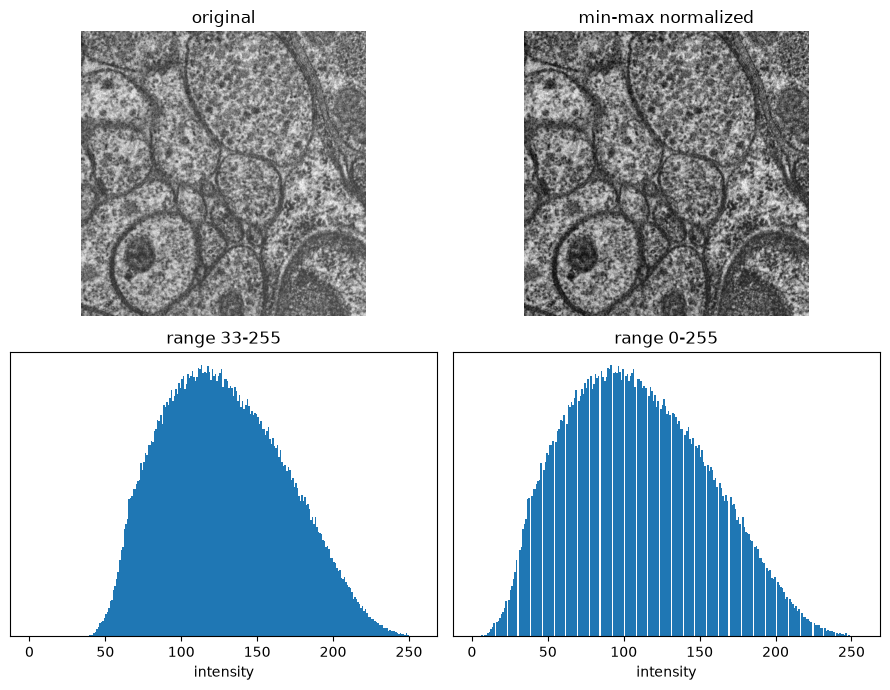

In [50]:
lo, hi = em.min(), em.max()
norm = (em.astype(float) - lo) / (hi - lo) * 255

fig, ax = plt.subplots(2, 2, figsize=(9, 7))
show(em, "original", ax[0, 0]); show(norm, "min-max normalized", ax[0, 1])
hist(em, f"range {em.min()}-{em.max()}", ax[1, 0]); hist(norm, "range 0-255", ax[1, 1])
plt.tight_layout(); plt.show()

### 5.2 A linear map cannot change the shape

s = a·r + b multiplies the standard deviation by exactly `a` and keeps the number of
distinct levels. The bump just gets wider.

In [51]:
a = 255 / (hi - lo)
print("slope a:", round(a, 3))
print("std ratio:", round(norm.std() / em.std(), 3))
print("distinct levels:", len(np.unique(em)), "->", len(np.unique(norm)))

slope a: 1.149
std ratio: 1.149
distinct levels: 223 -> 223


In [52]:
p1, p99 = np.percentile(em, (1, 99))
pct = np.clip((em.astype(float) - p1) / (p99 - p1) * 255, 0, 255)
print(f"percentile stretch {p1:.0f}-{p99:.0f}: std = {pct.std():.1f}, "
      f"clipped = {np.mean((pct == 0) | (pct == 255)) * 100:.1f}% of pixels")

percentile stretch 56-220: std = 61.6, clipped = 2.2% of pixels


A steeper line spreads the middle more but throws pixels off both ends. Still a bump.

---
# Part 6 · Histogram equalization

### 6.1 Equalize

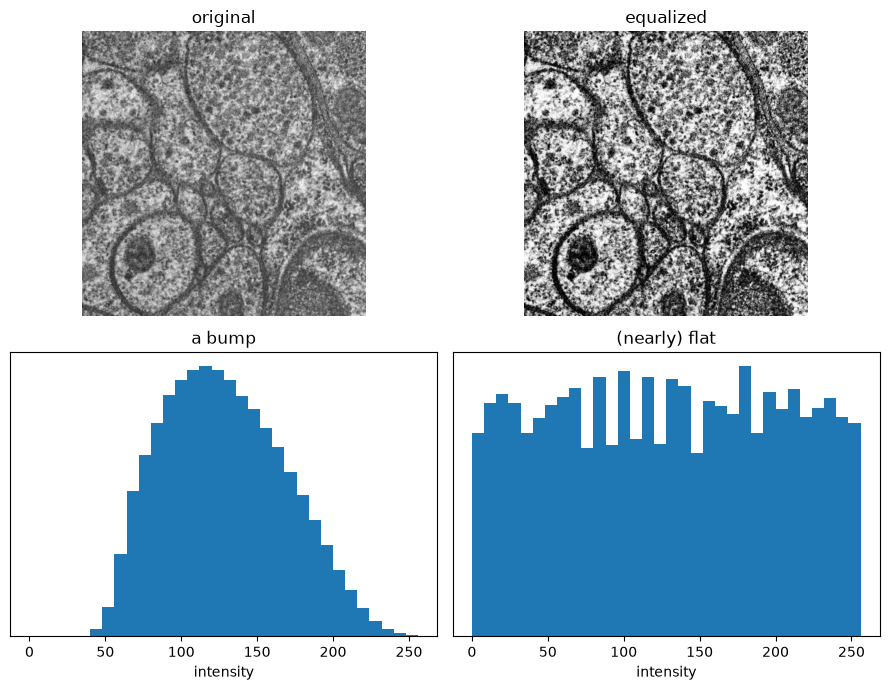

In [54]:
eq = exposure.equalize_hist(em) * 255

fig, ax = plt.subplots(2, 2, figsize=(9, 7))
show(em, "original", ax[0, 0]); show(eq, "equalized", ax[0, 1])
hist(em, "a bump", ax[1, 0], bins=32); hist(eq, "(nearly) flat", ax[1, 1], bins=32)
plt.tight_layout(); plt.show()

### 6.2 The output is (nearly) uniform

A uniform distribution on [0, 255] has standard deviation 255/√12 ≈ 73.6, and its CDF is a
straight line.

std: original 40.0  normalized 45.9  equalized 73.5  uniform 73.6


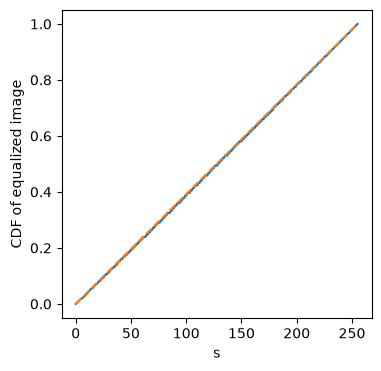

In [55]:
print("std: original", round(em.std(), 1), " normalized", round(norm.std(), 1),
      " equalized", round(eq.std(), 1), " uniform", round(255 / np.sqrt(12), 1))

F_eq = np.array([np.mean(eq <= s) for s in r])
plt.figure(figsize=(4, 4)); plt.plot(r, F_eq); plt.plot([0, 255], [0, 1], "--")
plt.xlabel("s"); plt.ylabel("CDF of equalized image"); plt.show()